# 01 · Exploratory Data Analysis — Telco Customer Churn
Goal: understand data quality, target balance and the strongest churn signals **before** modelling.
Any statistic that informs modelling is computed on the **training split only**, so nothing leaks from val/test.

*Run top to bottom (Run All). Figures are also saved to `reports/figures/`.*

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT   # works whether VS Code opens the folder or the notebook dir
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")

from src.config import RAW_FILE
from src.data import load_raw, clean, split
from src.evaluate import FIG_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)

raw = load_raw(RAW_FILE)
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1 · Data quality

In [2]:
print("duplicate customer IDs:", raw.customerID.duplicated().sum())
blank = raw.TotalCharges.astype(str).str.strip().eq("")
print("blank TotalCharges rows:", blank.sum(), "| all have tenure == 0:", (raw.loc[blank, "tenure"] == 0).all())
raw.dtypes.value_counts()

duplicate customer IDs: 0
blank TotalCharges rows: 11 | all have tenure == 0: True


str        18
int64       2
float64     1
Name: count, dtype: int64

**Finding:** `TotalCharges` loads as text because 11 rows are blank. They are exactly the `tenure == 0` customers (not billed yet), so the correct fix is `0`, not a median impute. Handled in `src/data.py::clean`.

In [3]:
df = clean(raw)
X_train, X_val, X_test, y_train, y_val, y_test = split(df)
train = X_train.assign(Churn=y_train)       # EDA on train only
print("train rows:", len(train), "| churn rate:", round(train.Churn.mean(), 3))

train rows: 4225 | churn rate: 0.265


## 2 · Target balance

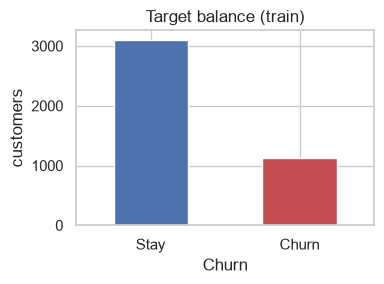

In [4]:
fig, ax = plt.subplots(figsize=(4, 3))
train.Churn.map({0: "Stay", 1: "Churn"}).value_counts().plot.bar(ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title("Target balance (train)"); ax.set_ylabel("customers"); plt.xticks(rotation=0)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_target_balance.png", dpi=150); plt.show()

**Finding:** ~26.5% churn → moderate imbalance. Accuracy is misleading (a model that says *nobody churns* is ~73% accurate), so we judge on **PR-AUC**, precision/recall and business cost.

## 3 · Categorical drivers of churn

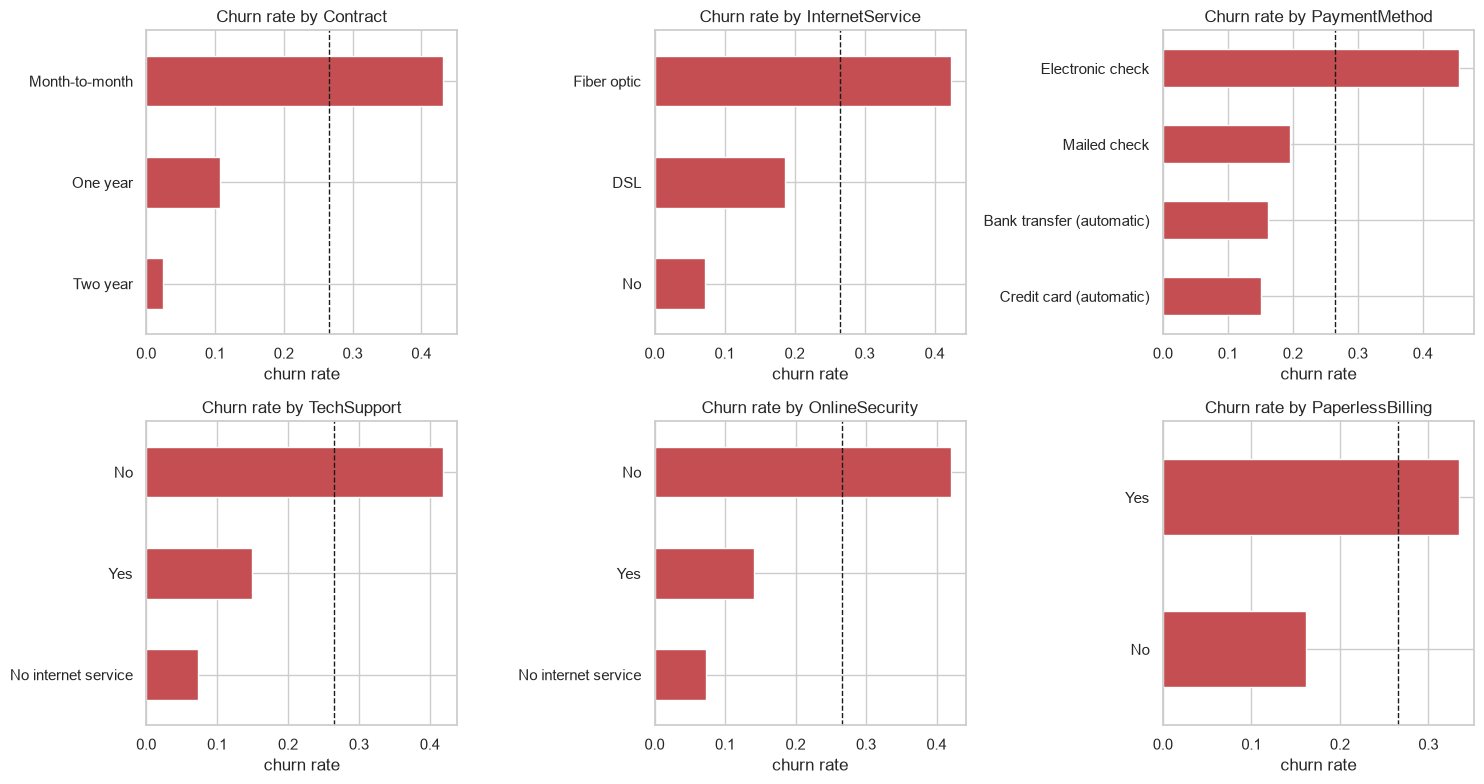

In [5]:
cats = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cats):
    r = train.groupby(c).Churn.mean().sort_values()
    r.plot.barh(ax=ax, color="#C44E52"); ax.axvline(train.Churn.mean(), ls="--", c="k", lw=1)
    ax.set_title(f"Churn rate by {c}"); ax.set_xlabel("churn rate"); ax.set_ylabel("")
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_categorical_churn.png", dpi=150); plt.show()

**Findings:** month-to-month contracts, fiber optic, electronic-check payers and customers *without* tech support / online security churn far above the ~26.5% average. Two-year contracts are the safest segment.

## 4 · Numeric drivers

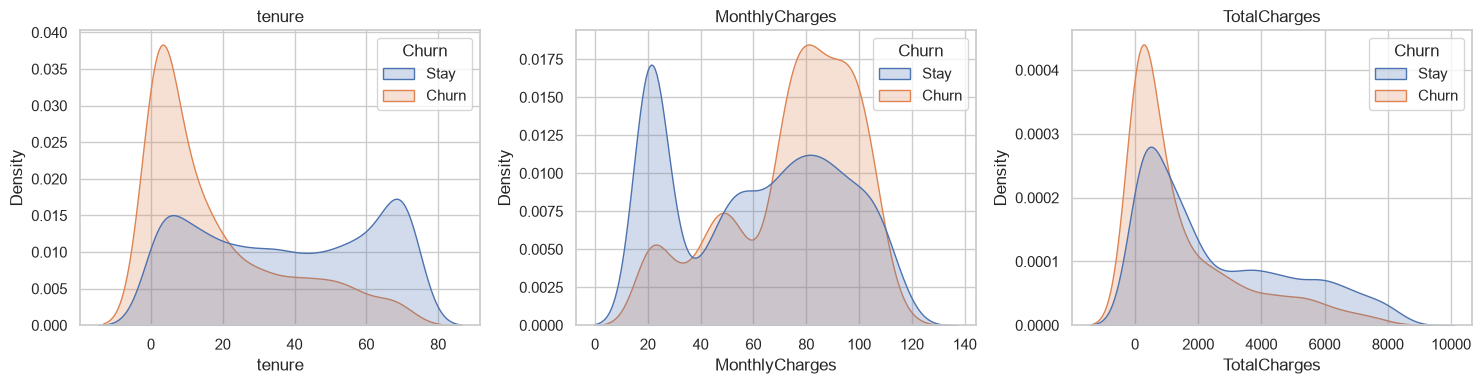

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.kdeplot(data=train, x=c, hue=train.Churn.map({0: "Stay", 1: "Churn"}), fill=True, common_norm=False, ax=ax)
    ax.set_title(c)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_numeric_churn.png", dpi=150); plt.show()

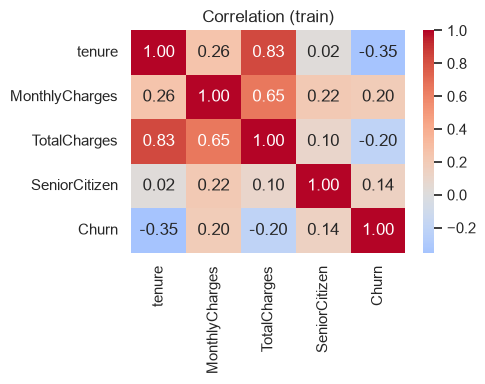

In [7]:
num = train[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]]
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax); ax.set_title("Correlation (train)")
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_correlation.png", dpi=150); plt.show()

**Findings:** churners are concentrated in the first ~12 months and pay *more* per month. `TotalCharges` is largely tenure × monthly charge (corr ≈ 0.83 with tenure), hence the engineered `avg_monthly_paid` / `charge_vs_history` features in `src/features.py`.

## 5 · Interaction: contract × tenure

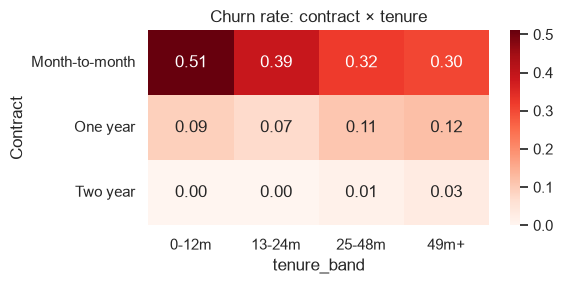

In [8]:
t = train.assign(tenure_band=pd.cut(train.tenure, [-1, 12, 24, 48, 100], labels=["0-12m", "13-24m", "25-48m", "49m+"]))
pt = t.pivot_table(index="Contract", columns="tenure_band", values="Churn", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(6, 3))
sns.heatmap(pt, annot=True, fmt=".2f", cmap="Reds", ax=ax); ax.set_title("Churn rate: contract × tenure")
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_contract_tenure.png", dpi=150); plt.show()

## 6 · Takeaways for modelling
1. Imbalance is moderate → compare *no handling*, class weights and SMOTE; evaluate on PR-AUC, not accuracy.
2. Contract type and tenure dominate → expect strong signal even from a linear baseline; boosted-tree gains will be incremental.
3. `TotalCharges` is redundant with tenure × charges → engineered ratio features instead of relying on the raw column.
4. No duplicates and one data-quality issue (blank `TotalCharges`), fixed deterministically → no leakage risk from cleaning.